# Supplementary Figure 3. The STP model fits the On/Off statistics about as well as the NMDA model

The same rate model with short-term facilitation (Tsodyks-Markram, tau_f = 1.5 s) in place of NMDA gating
(`ratemodel.params('stp')`), fitted the same way to the all-units decoder only; the other six decoded
populations are predictions of both models. About 2 minutes.

In [1]:
from nmdaint import ratemodel, readout
from plots import figS3, style

## Parameters

In [2]:
NMDA = ratemodel.params('nmda')
STP = ratemodel.params('stp')            # e.g. ratemodel.params('stp', tau_f=500)
N_TRIALS, SEED = 2112, 1

In [3]:
ses, hist = readout.load_data()
models = {name: readout.summary(readout.evaluate(p, ses, n_trials=N_TRIALS, seed=SEED), ses, hist)
          for name, p in (('NMDA', NMDA), ('STP', STP))}
print('fit loss, summed over the 7 populations:', {k: round(v.loss.sum()) for k, v in models.items()})
print('memory held:', {k: round(v.memory.iloc[0], 3) for k, v in models.items()})

fit loss, summed over the 7 populations: {'NMDA': 74, 'STP': 79}
memory held: {'NMDA': np.float64(0.984), 'STP': np.float64(1.0)}


## Figure

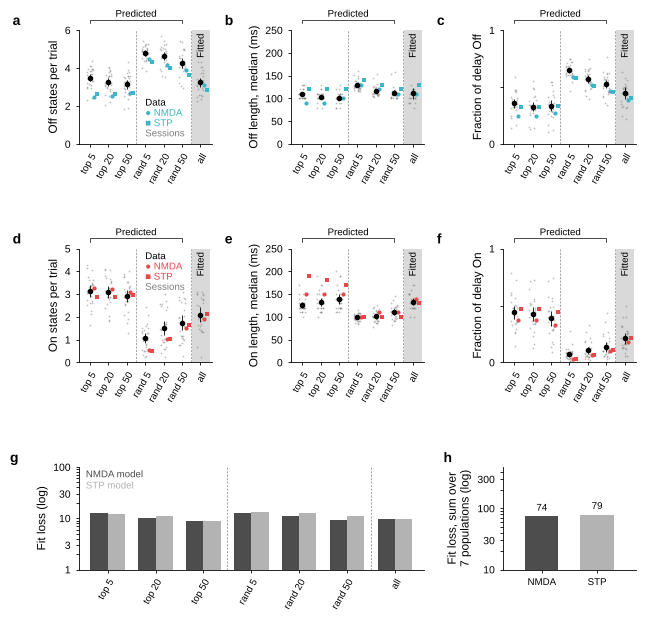

In [4]:
fig = figS3.draw(ses, models)
style.save(fig, '../figures/figS3.png')